# 01 · Exploratory data analysis

**Goal:** understand the raw HDB resale data before cleaning or modeling it: what each column holds, what is missing or malformed, how prices are distributed and how they move over time.

**Output:** a list of findings, each turned into a cleaning or modeling decision (recorded at the end of this notebook). Reusable code goes into the `hdb_resale` package, never only here.

**Data:** the DVC-versioned raw snapshot `data/raw/resale.csv` (see `data/raw/snapshot.json`). To get it: `uv run dvc pull`.

**Rule for this notebook:** we explore the whole dataset's *structure*, but take no modeling decision from the most recent 12 months: they are the test period of the rolling backtest (project ADR-0001).

## Contents

1. Load and structure: columns, types, missing values
2. Prices: distribution and trend over time
3. What drives price besides time

## 1. Load and structure

Load the snapshot exactly as published: no type conversion yet, so we see what pandas infers on its own.

In [1]:
from pathlib import Path

import pandas as pd

# The notebook runs from notebooks/, the data lives at the project root
PROJECT_ROOT = Path.cwd().parent
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "resale.csv"

raw = pd.read_csv(RAW_PATH)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

242,537 rows x 11 columns


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979,61 years 04 months,232000.0
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978,60 years 07 months,250000.0
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,262000.0
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980,62 years 01 month,265000.0
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,265000.0


### Column types and missing values

For each column: the type pandas inferred, how many values are missing, how many distinct values it has, and one example.

In [2]:
# One row per column: inferred type, missing values, distinct values, an example
structure = pd.DataFrame(
    {
        "dtype": raw.dtypes.astype(str),
        "missing": raw.isna().sum(),
        "distinct": raw.nunique(),
        "example": raw.iloc[0],
    }
)
structure

,dtype,missing,distinct,example
month,str,0,118,2017-01
town,str,0,26,ANG MO KIO
flat_type,str,0,7,2 ROOM
block,str,0,2788,406
street_name,str,0,580,ANG MO KIO AVE 10
storey_range,str,0,17,10 TO 12
floor_area_sqm,float64,0,196,44.0
flat_model,str,0,21,Improved
lease_commence_date,int64,0,58,1979
remaining_lease,str,0,703,61 years 04 months


### Placeholder values

No value is missing, but datasets sometimes encode "unknown" as a fake value (0, -1, 9999, "NA", "UNKNOWN"). Check the extremes of the numeric columns and every category of the short text columns.

In [3]:
# Placeholder check, numbers: impossible extremes (0, -1, 9999) would show up as min or max
print(raw[["floor_area_sqm", "lease_commence_date", "resale_price"]].agg(["min", "max"]))

# Placeholder check, text: values like "UNKNOWN", "NA" or "-" in any text column
text_cols = raw.select_dtypes("str").columns
suspects = raw[text_cols].apply(
    lambda s: s.str.strip().str.upper().isin(["", "NA", "N/A", "NIL", "NULL", "UNKNOWN", "-"])
)
print("\nSuspect text values:", int(suspects.sum().sum()))

# Every category of the short categorical columns, rarest last
for col in ["flat_type", "storey_range", "flat_model"]:
    print(f"\n{col}:", raw[col].value_counts().to_dict())

     floor_area_sqm  lease_commence_date  resale_price
min            31.0                 1966      140000.0
max           366.7                 2023     1728000.0



Suspect text values: 0

flat_type: {'4 ROOM': 103086, '5 ROOM': 59348, '3 ROOM': 57542, 'EXECUTIVE': 17281, '2 ROOM': 5100, 'MULTI-GENERATION': 91, '1 ROOM': 89}

storey_range: {'04 TO 06': 55625, '07 TO 09': 50832, '10 TO 12': 45285, '01 TO 03': 42520, '13 TO 15': 23439, '16 TO 18': 10981, '19 TO 21': 4757, '22 TO 24': 3321, '25 TO 27': 2072, '28 TO 30': 1363, '31 TO 33': 747, '34 TO 36': 655, '37 TO 39': 533, '40 TO 42': 260, '43 TO 45': 76, '46 TO 48': 52, '49 TO 51': 19}

flat_model: {'Model A': 87511, 'Improved': 59204, 'New Generation': 29366, 'Premium Apartment': 26490, 'Simplified': 9248, 'Apartment': 8668, 'Maisonette': 6629, 'Standard': 6423, 'DBSS': 3838, 'Model A2': 2718, '2-room': 519, 'Model A-Maisonette': 422, 'Adjoined flat': 416, 'Type S1': 393, 'Type S2': 199, 'Premium Apartment Loft': 140, 'Terrace': 123, 'Multi Generation': 91, '3Gen': 84, 'Improved-Maisonette': 33, 'Premium Maisonette': 22}


### Findings (section 1)

- **242,537 resale transactions**, Jan 2017 to Oct 2026 (the last month is incomplete: registration lag), 11 columns, **no missing values and no placeholder values** ("NA", "UNKNOWN", 0, 9999).
- **Extremes are genuine.** The largest flat (366.7 m², S\$1.57M) is an HDB Terrace house in Kallang/Whampoa, a rare 1970s house-type flat with its own land, not a data error.
- **Types to convert during cleaning:**
  - `month` → a monthly period (the registration month).
  - `remaining_lease` ("61 years 04 months") → a number of years; every value follows that pattern.
  - `storey_range` ("10 TO 12") → the middle storey, keeping the order of the 17 ranges.
  - `block` stays **text**: 37% of blocks contain letters ("406A"), it's an identifier, not a quantity.
- **Categories:** 26 towns, 7 flat types (1-room and multi-generation are rare: about 90 sales each), 21 flat models (HDB building designs and eras). Several flat models are rare (22 to 140 sales) and some repeat the flat type (`2-room`, `Multi Generation`): **group** them into broader families before modeling.

## 2. Prices: distribution and trend over time

**Hypotheses:** right-skewed (many cheaper sales, few very expensive ones); prices up roughly 8% from 2017 to 2026.

In [4]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# Chart style: recessive grid and axes, thin lines; one fixed colour order for categories
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "axes.edgecolor": "#52514e",
        "axes.labelcolor": "#0b0b0b",
        "text.color": "#0b0b0b",
        "lines.linewidth": 2,
    }
)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

# Prices in thousands of S$ read more easily on axes
thousands = mticker.FuncFormatter(lambda x, _: f"{x / 1000:,.0f}k")

### Distribution

Summary statistics first, then the histogram on a normal scale and on a log scale. A log scale shows whether the skew comes from a multiplicative spread (prices that differ by a percentage rather than a fixed amount).

In [5]:
# Key quantiles of the resale price, in S$
raw["resale_price"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(0)

count     242537.0
mean      536374.0
std       193393.0
min       140000.0
1%        235000.0
25%       392000.0
50%       505000.0
75%       645000.0
99%      1110000.0
max      1728000.0
Name: resale_price, dtype: float64

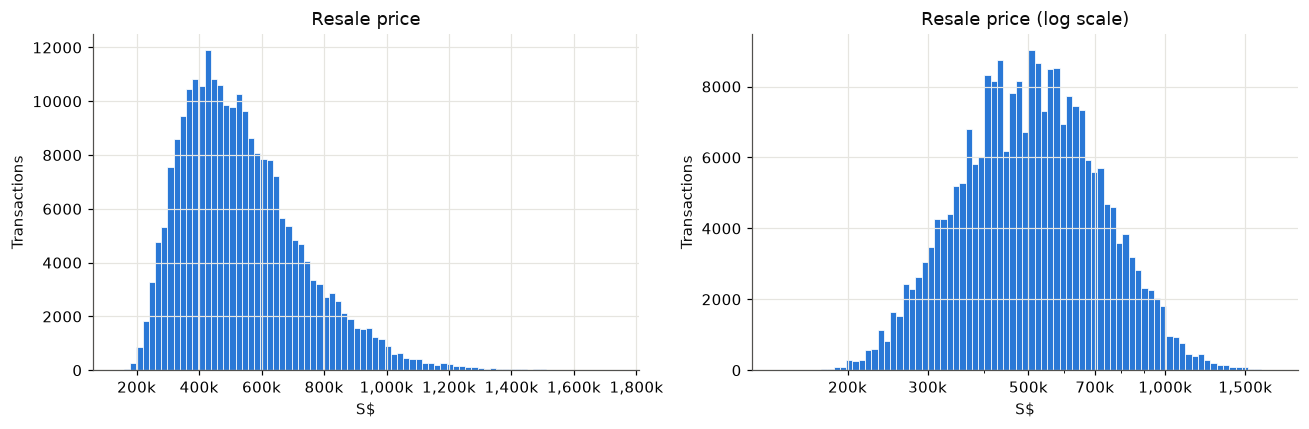

In [6]:
# Same prices, two scales: linear (left) and log (right)
fig, (ax_lin, ax_log) = plt.subplots(1, 2, figsize=(12, 4))

ax_lin.hist(
    raw["resale_price"], bins=80, color=SERIES[0], edgecolor="white", linewidth=0.5
)
ax_lin.xaxis.set_major_formatter(thousands)
ax_lin.set(title="Resale price", xlabel="S$", ylabel="Transactions")

log_bins = np.logspace(
    np.log10(raw["resale_price"].min()), np.log10(raw["resale_price"].max()), 80
)
ax_log.hist(
    raw["resale_price"],
    bins=log_bins,
    color=SERIES[0],
    edgecolor="white",
    linewidth=0.5,
)
ax_log.set_xscale("log")
ax_log.xaxis.set_major_locator(
    mticker.FixedLocator([200e3, 300e3, 500e3, 700e3, 1e6, 1.5e6])
)
ax_log.xaxis.set_major_formatter(thousands)
ax_log.xaxis.set_minor_formatter(mticker.NullFormatter())
ax_log.set(title="Resale price (log scale)", xlabel="S$", ylabel="Transactions")

plt.tight_layout()

### Trend over time

Median price per registration month, overall and for the four main flat types. The last month is incomplete (registration lag), so its median rests on fewer sales.

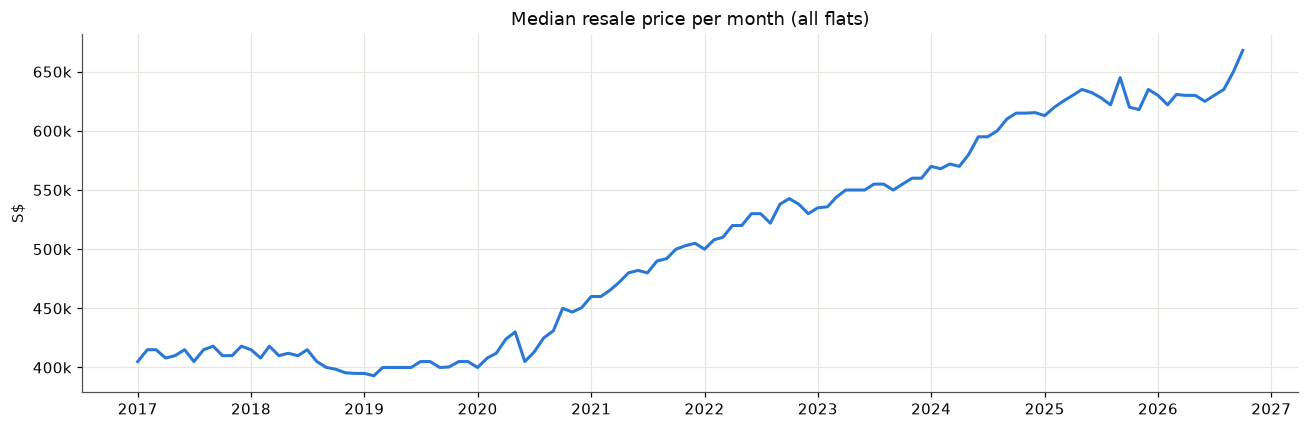

In [7]:
# Median price per month, overall
monthly = raw.groupby("month")["resale_price"].agg(["median", "size"])
monthly.index = pd.PeriodIndex(monthly.index, freq="M").to_timestamp()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly["median"], color=SERIES[0])
ax.yaxis.set_major_formatter(thousands)
ax.set(title="Median resale price per month (all flats)", ylabel="S$")
plt.tight_layout()

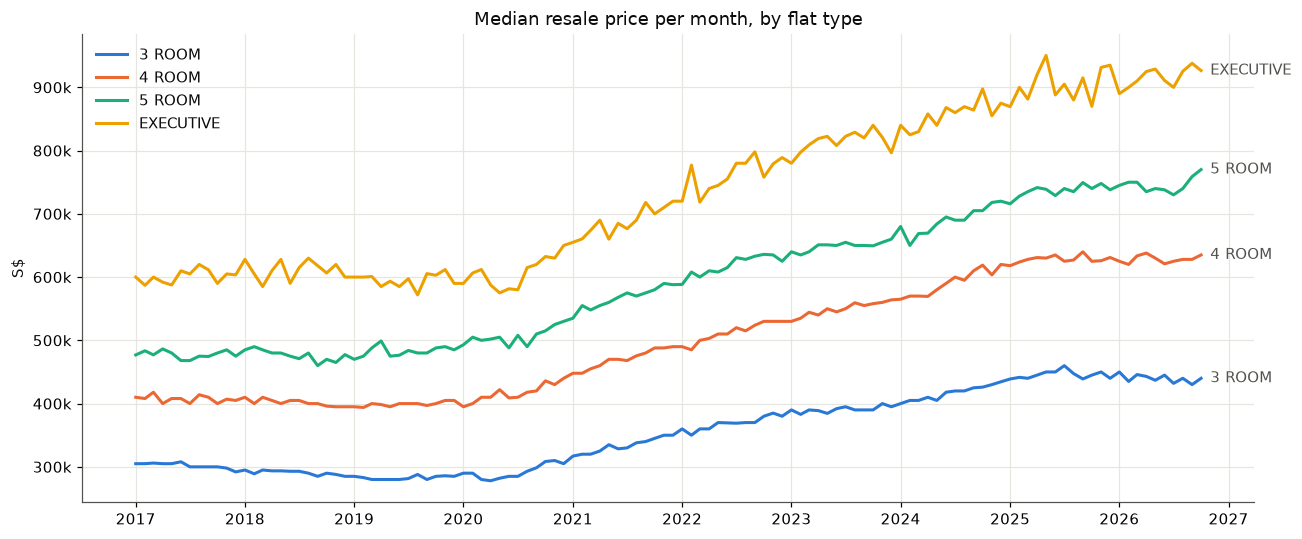

In [8]:
# Median price per month for the four most common flat types (the other three are rare)
main_types = raw["flat_type"].value_counts().index[:4].sort_values()
by_type = (
    raw[raw["flat_type"].isin(main_types)]
    .groupby(["month", "flat_type"])["resale_price"]
    .median()
    .unstack()
)
by_type.index = pd.PeriodIndex(by_type.index, freq="M").to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
for color, flat_type in zip(SERIES, main_types, strict=True):
    ax.plot(by_type.index, by_type[flat_type], color=color, label=flat_type)
    # Direct label at the end of each line, so identity doesn't rely on colour alone
    ax.annotate(
        flat_type,
        (by_type.index[-1], by_type[flat_type].iloc[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        color="#52514e",
    )
ax.yaxis.set_major_formatter(thousands)
ax.legend(loc="upper left", frameon=False)
ax.set(title="Median resale price per month, by flat type", ylabel="S$")
plt.tight_layout()

In [9]:
# How much did the median rise? First full year (2017) vs the last 12 complete months
year = raw["month"].str[:4]
first_year = raw.loc[year == "2017", "resale_price"].median()
complete_months = sorted(raw["month"].unique())[
    :-1
]  # drop the incomplete current month
last_12 = raw.loc[raw["month"].isin(complete_months[-12:]), "resale_price"].median()
print(f"2017 median:                 S${first_year:,.0f}")
print(
    f"Last 12 full months median:  S${last_12:,.0f}  ({complete_months[-12]} to {complete_months[-1]})"
)
print(f"Change:                      {last_12 / first_year - 1:+.0%}")

2017 median:                 S$410,000
Last 12 full months median:  S$630,000  (2025-10 to 2026-09)
Change:                      +54%


### Findings (section 2)

- **Median S\$505k** over 2017–2026, about S\$630k recently.
- **Right-skewed** (skewness ≈ 1), as expected, and **nearly symmetric on a log scale**: prices differ multiplicatively, so model the **log of the price**.
- **Three regimes:** flat 2017–2019, a sharp rise 2020–2025 (about +50%), a plateau since mid-2025. The +8% hypothesis reflected only the recent plateau.
- The rise holds **within every flat type**, so it's a real price change, not a composition effect (more large flats being sold).
- **Modeling consequences:** the model must know *when* a sale happened, and the regime changes make the training window length (expanding vs sliding) worth testing in the backtest.

## 3. What drives price besides time

**Hypotheses:** floor area is the strongest driver, strongly collinear with flat type (room sizes are fairly standard in Singapore); location (town) is a major driver; remaining lease is a major driver, collinear with lease commencement date; storey matters, but less.

**Data:** sales before the backtest test period only (see the notebook rule above), since this section informs modeling decisions.

To compare flats of different sizes fairly, most charts below use the **price per square metre**.

*The quick conversions in this section (lease, storey) are exploration only: the real cleaning code goes into the package in the next sub-step.*

In [10]:
# Exploration-only helper columns (proper cleaning comes in the package later)
# Test period of the rolling backtest (last 12 complete months, project ADR-0001): left out,
# so no modeling decision below is drawn from the months the backtest scores
TEST_START = "2025-10"
eda = raw[raw["month"] < TEST_START].copy()
print(f"{len(eda):,} sales before {TEST_START} ({len(eda) / len(raw):.0%} of the snapshot)")
eda["price_per_sqm"] = eda["resale_price"] / eda["floor_area_sqm"]

# "61 years 04 months" -> 61.33 years
lease_parts = (
    eda["remaining_lease"].str.extract(r"(\d+) years?(?: (\d+) months?)?").astype(float)
)
eda["remaining_lease_years"] = lease_parts[0] + lease_parts[1].fillna(0) / 12

# "10 TO 12" -> 11 (middle storey)
storey_bounds = eda["storey_range"].str.extract(r"(\d+) TO (\d+)").astype(int)
eda["storey_mid"] = storey_bounds.mean(axis=1)

eda[
    [
        "remaining_lease",
        "remaining_lease_years",
        "storey_range",
        "storey_mid",
        "price_per_sqm",
    ]
].head()

217,046 sales before 2025-10 (89% of the snapshot)


,remaining_lease,remaining_lease_years,storey_range,storey_mid,price_per_sqm
0,61 years 04 months,61.333333,10 TO 12,11.0,5272.727273
1,60 years 07 months,60.583333,01 TO 03,2.0,3731.343284
2,62 years 05 months,62.416667,01 TO 03,2.0,3910.447761
3,62 years 01 month,62.083333,04 TO 06,5.0,3897.058824
4,62 years 05 months,62.416667,01 TO 03,2.0,3955.223881


### Size: floor area and flat type

Correlation, floor area vs price: 0.58
Bins shown: 32, covering 100.0% of sales


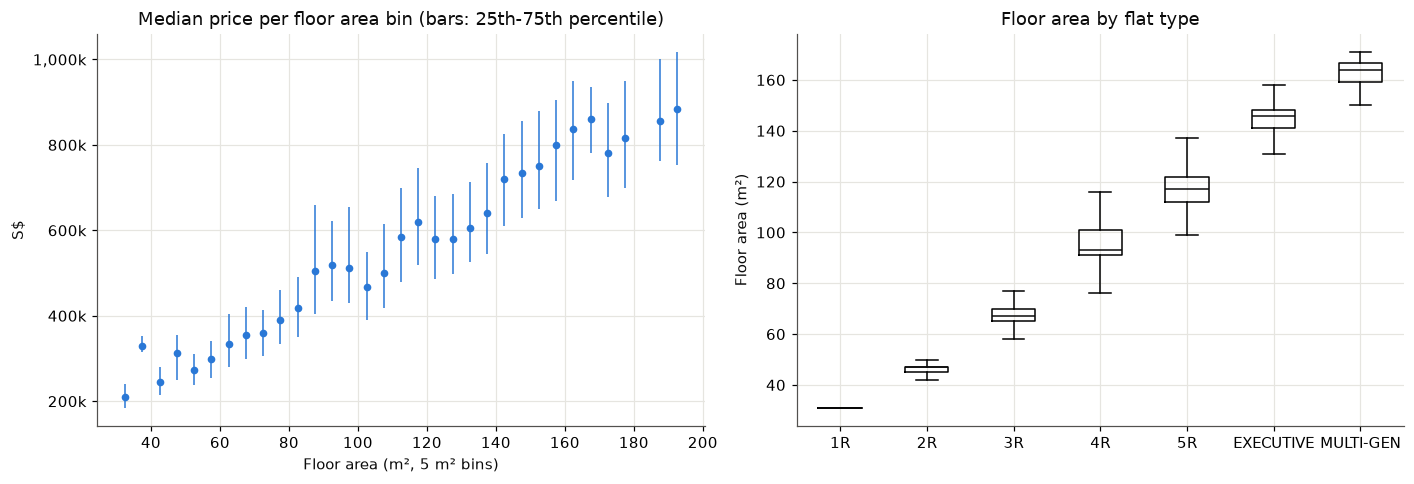

In [11]:
# Price vs floor area, binned: median price per 5 m² bin, error bar = 25th to 75th percentile
fig, (ax_area, ax_type) = plt.subplots(1, 2, figsize=(13, 4.5))

area_bin = (eda["floor_area_sqm"] // 5) * 5 + 2.5  # bin centre, e.g. 67 m² -> 67.5
binned = eda.groupby(area_bin)["resale_price"].agg(
    median="median",
    q25=lambda s: s.quantile(0.25),
    q75=lambda s: s.quantile(0.75),
    size="size",
)
binned = binned[binned["size"] >= 50]  # a median from a handful of sales is noise

ax_area.errorbar(
    binned.index,
    binned["median"],
    yerr=[binned["median"] - binned["q25"], binned["q75"] - binned["median"]],
    fmt="o",
    markersize=4,
    color=SERIES[0],
    ecolor=SERIES[0],
    elinewidth=1,
)
ax_area.yaxis.set_major_formatter(thousands)
ax_area.set(
    title="Median price per floor area bin (bars: 25th-75th percentile)",
    xlabel="Floor area (m², 5 m² bins)",
    ylabel="S$",
)

# Floor area per flat type, ordered from smallest to largest
type_order = [
    "1 ROOM",
    "2 ROOM",
    "3 ROOM",
    "4 ROOM",
    "5 ROOM",
    "EXECUTIVE",
    "MULTI-GENERATION",
]
ax_type.boxplot(
    [eda.loc[eda["flat_type"] == t, "floor_area_sqm"] for t in type_order],
    tick_labels=[
        t.replace(" ROOM", "R").replace("MULTI-GENERATION", "MULTI-GEN")
        for t in type_order
    ],
    showfliers=False,
    medianprops={"color": "#0b0b0b"},
)
ax_type.set(title="Floor area by flat type", ylabel="Floor area (m²)")
plt.tight_layout()

print(
    f"Correlation, floor area vs price: {eda['floor_area_sqm'].corr(eda['resale_price']):.2f}"
)
print(f"Bins shown: {len(binned)}, covering {binned['size'].sum() / len(eda):.1%} of sales")

### Location: town

Most / least expensive town: 1.7x per m²
Same, flats built 1975-1990 only: 1.8x per m²


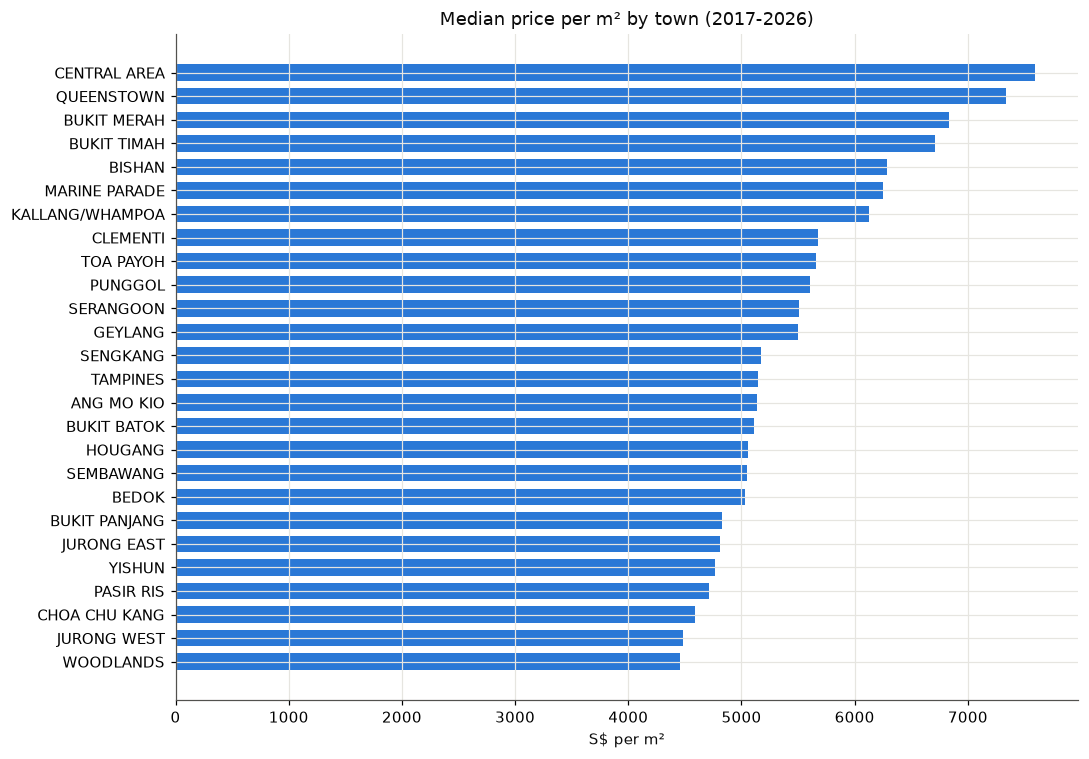

In [12]:
# Median price per m² by town, sorted: isolates location from flat size
town_ppsqm = eda.groupby("town")["price_per_sqm"].median().sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(town_ppsqm.index, town_ppsqm.values, color=SERIES[0], height=0.7)
ax.set(title="Median price per m² by town (2017-2026)", xlabel="S$ per m²")
plt.tight_layout()

print(f"Most / least expensive town: {town_ppsqm.max() / town_ppsqm.min():.1f}x per m²")

# Same comparison among flats of similar age only (lease start 1975-1990), so newness can't explain it
same_age = eda[eda["lease_commence_date"].between(1975, 1990)]
same_age_ppsqm = same_age.groupby("town")["price_per_sqm"].median()
print(f"Same, flats built 1975-1990 only: {same_age_ppsqm.max() / same_age_ppsqm.min():.1f}x per m²")

### Age: remaining lease

Correlation, remaining lease vs 99 - age: 1.000
Gap between the two: median 0.50 years, 99th percentile 1.00 years


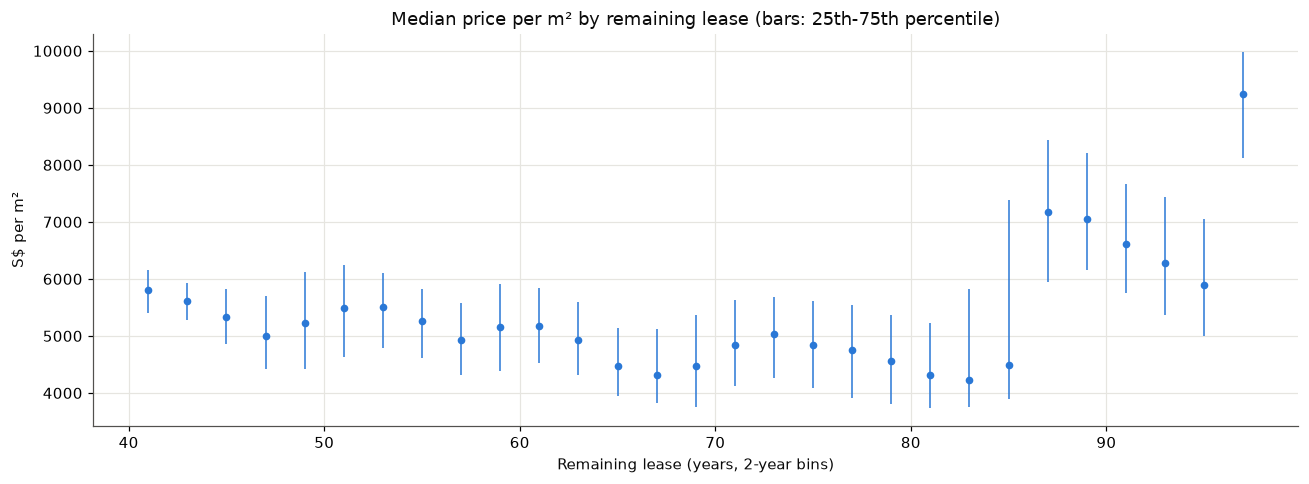

In [13]:
# Remaining lease vs price per m², binned: median per 2-year bin, error bar = 25th to 75th percentile
lease_bin = (eda["remaining_lease_years"] // 2) * 2 + 1  # bin centre, e.g. 61.3 years -> 61
lease_binned = eda.groupby(lease_bin)["price_per_sqm"].agg(
    median="median",
    q25=lambda s: s.quantile(0.25),
    q75=lambda s: s.quantile(0.75),
    size="size",
)
lease_binned = lease_binned[lease_binned["size"] >= 50]  # a median from a handful of sales is noise

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.errorbar(
    lease_binned.index,
    lease_binned["median"],
    yerr=[
        lease_binned["median"] - lease_binned["q25"],
        lease_binned["q75"] - lease_binned["median"],
    ],
    fmt="o",
    markersize=4,
    color=SERIES[0],
    ecolor=SERIES[0],
    elinewidth=1,
)
ax.set(
    title="Median price per m² by remaining lease (bars: 25th-75th percentile)",
    xlabel="Remaining lease (years, 2-year bins)",
    ylabel="S$ per m²",
)
plt.tight_layout()

# HDB leases are 99 years: remaining lease should be 99 - (sale year - lease start)
sale_year = (
    eda["month"].str[:4].astype(int) + (eda["month"].str[5:7].astype(int) - 1) / 12
)
implied_remaining = 99 - (sale_year - eda["lease_commence_date"])
gap = (eda["remaining_lease_years"] - implied_remaining).abs()
print(
    f"Correlation, remaining lease vs 99 - age: {eda['remaining_lease_years'].corr(implied_remaining):.3f}"
)
print(
    f"Gap between the two: median {gap.median():.2f} years, 99th percentile {gap.quantile(0.99):.2f} years"
)

The chart above mixes age with location and time: old flats are concentrated in expensive central towns, and the newest flats were mostly resold during the 2020-2025 rise. To isolate age, compare each sale with **comparable sales: same town, same month**.

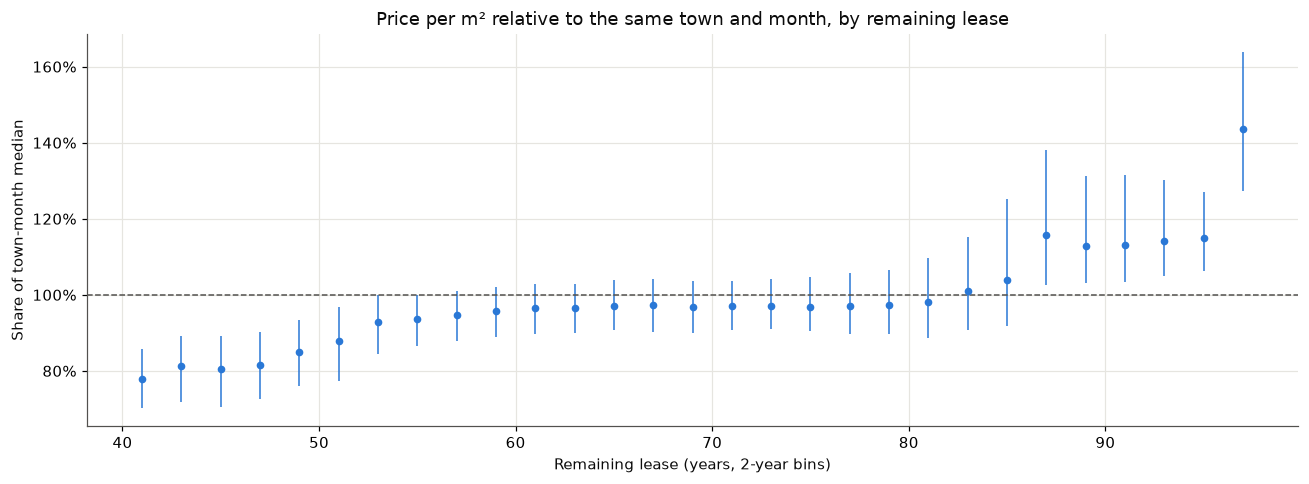

In [14]:
# Same chart, holding location and time fixed: each sale's price per m² relative to the
# median of its own town in its own month (1.10 = 10% above comparable sales)
town_month_median = eda.groupby(["town", "month"])["price_per_sqm"].transform("median")
eda["relative_ppsqm"] = eda["price_per_sqm"] / town_month_median

lease_relative = eda.groupby(lease_bin)["relative_ppsqm"].agg(
    median="median",
    q25=lambda s: s.quantile(0.25),
    q75=lambda s: s.quantile(0.75),
    size="size",
)
lease_relative = lease_relative[lease_relative["size"] >= 50]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.errorbar(
    lease_relative.index,
    lease_relative["median"],
    yerr=[
        lease_relative["median"] - lease_relative["q25"],
        lease_relative["q75"] - lease_relative["median"],
    ],
    fmt="o",
    markersize=4,
    color=SERIES[0],
    ecolor=SERIES[0],
    elinewidth=1,
)
ax.axhline(1, color="#52514e", linewidth=1, linestyle="--")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set(
    title="Price per m² relative to the same town and month, by remaining lease",
    xlabel="Remaining lease (years, 2-year bins)",
    ylabel="Share of town-month median",
)
plt.tight_layout()

### Height: storey

,median,size
storey_mid,,
2.0,4738.095238,38297
5.0,4946.236559,49747
8.0,5108.695652,45507
11.0,5217.391304,40547
14.0,5580.357143,20919
17.0,5983.333333,9797
20.0,6760.330579,4201
23.0,7089.552239,2944
26.0,8076.923077,1839


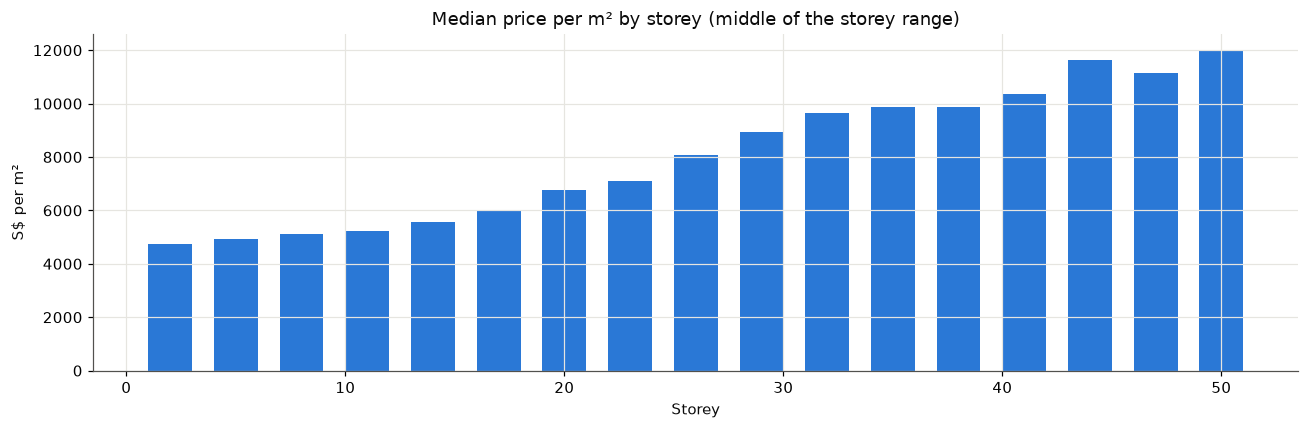

In [15]:
# Median price per m² per storey range, from lowest to highest floor
storey = eda.groupby("storey_mid")["price_per_sqm"].agg(["median", "size"])

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(storey.index, storey["median"], width=2, color=SERIES[0])
ax.set(
    title="Median price per m² by storey (middle of the storey range)",
    xlabel="Storey",
    ylabel="S$ per m²",
)
plt.tight_layout()

storey

Storey is confounded too: HDB built low-rise blocks in the 1970s-90s and very tall ones only recently, mostly in central towns, so "high floor" largely means "new, central flat". Comparing each sale with **the same block in the same year** cancels location, age and time at once, leaving the effect of height alone.

,median,q25,q75,size
storey_mid,,,,
2.0,0.95,0.91,0.99,13541
5.0,0.98,0.94,1.00,19696
8.0,1.00,0.97,1.03,19357
11.0,1.01,0.99,1.04,17825
14.0,1.02,1.00,1.05,11395
17.0,1.02,1.00,1.06,5854
20.0,1.02,1.00,1.05,2619
23.0,1.02,1.00,1.05,1940
26.0,1.03,1.00,1.06,1365


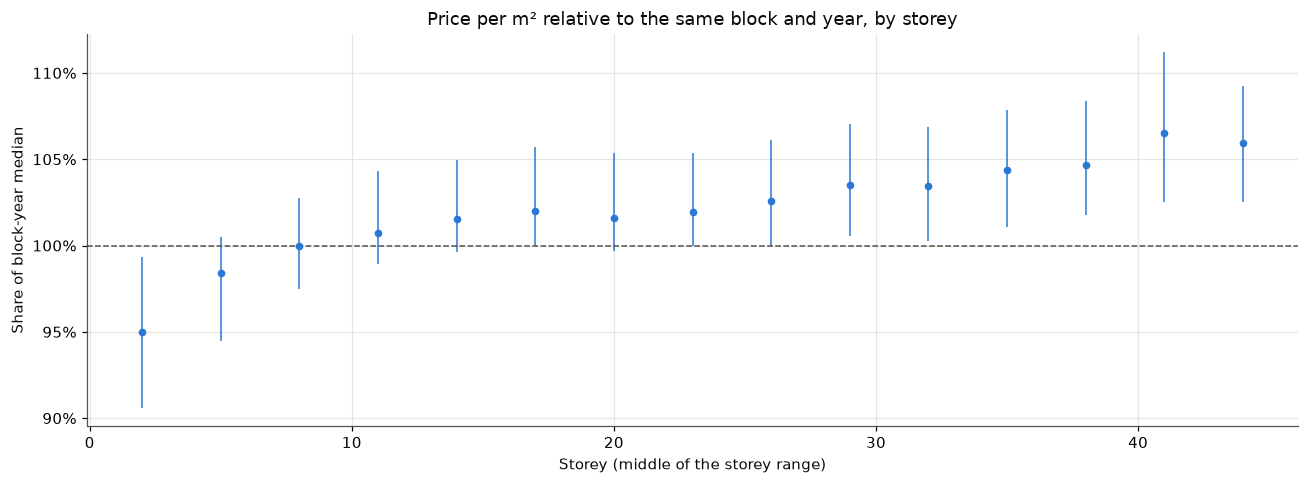

In [16]:
# Same chart, holding location, age and time fixed: each sale's price per m² relative to the
# median of its own block in its own year (a block is a building: block number + street)
block_id = eda["block"] + " " + eda["street_name"]
block_year = [block_id, eda["month"].str[:4]]
block_year_median = eda.groupby(block_year)["price_per_sqm"].transform("median")
block_year_size = eda.groupby(block_year)["price_per_sqm"].transform("size")
eda["block_relative_ppsqm"] = eda["price_per_sqm"] / block_year_median

# Blocks with at least 5 sales that year, so the block median is meaningful
storey_relative = (
    eda[block_year_size >= 5]
    .groupby("storey_mid")["block_relative_ppsqm"]
    .agg(
        median="median",
        q25=lambda s: s.quantile(0.25),
        q75=lambda s: s.quantile(0.75),
        size="size",
    )
)
storey_relative = storey_relative[storey_relative["size"] >= 50]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.errorbar(
    storey_relative.index,
    storey_relative["median"],
    yerr=[
        storey_relative["median"] - storey_relative["q25"],
        storey_relative["q75"] - storey_relative["median"],
    ],
    fmt="o",
    markersize=4,
    color=SERIES[0],
    ecolor=SERIES[0],
    elinewidth=1,
)
ax.axhline(1, color="#52514e", linewidth=1, linestyle="--")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set(
    title="Price per m² relative to the same block and year, by storey",
    xlabel="Storey (middle of the storey range)",
    ylabel="Share of block-year median",
)
plt.tight_layout()

storey_relative.round(2)

### All numeric drivers together

Spearman correlation (based on ranks, so it captures any monotonic relationship, not just straight lines), including time as a number of months since Jan 2017.

In [17]:
# Rank correlations between the numeric drivers and the log price
eda["months_since_2017"] = (sale_year - 2017) * 12
eda["log_price"] = np.log(eda["resale_price"])
numeric = [
    "log_price",
    "floor_area_sqm",
    "remaining_lease_years",
    "lease_commence_date",
    "storey_mid",
    "months_since_2017",
]
eda[numeric].corr(method="spearman").round(2)

,log_price,floor_area_sqm,remaining_lease_years,lease_commence_date,storey_mid,months_since_2017
log_price,1.00,0.61,0.33,0.41,0.25,0.41
floor_area_sqm,0.61,1.00,0.16,0.16,0.01,-0.04
remaining_lease_years,0.33,0.16,1.00,0.98,0.24,-0.06
lease_commence_date,0.41,0.16,0.98,1.00,0.24,0.13
storey_mid,0.25,0.01,0.24,0.24,1.00,0.01
months_since_2017,0.41,-0.04,-0.06,0.13,0.01,1.00


### Findings (section 3)

- **Size.** Price rises almost linearly with floor area: the median goes from about S\$210k at 30–35 m² to about S\$880k at 190 m². The spread within each size is wide (often S\$100–250k between the 25th and 75th percentiles), so the other drivers carry a lot of information. Flat type and floor area are **strongly but not perfectly related** (a 4-room spans about 76–116 m²): the model keeps both, and the backtest tests dropping one (ablation).
- **Location.** Town is a **major driver**: a **1.7x** gap in median price per m² between the cheapest towns (Woodlands, Jurong West) and the most expensive (Central Area, Queenstown), and as large (1.8x) among flats of similar age. Central, mature estates are the most expensive even though their flats are older.
- **Age.** Remaining lease is exactly 99 years minus the flat's age at sale: given the sale month, it adds nothing over the lease commencement date, so the model uses **one of the two**. Raw, its effect on price looks weak, because location and time are confounders: old flats are concentrated in expensive central towns, and the newest were mostly resold during the 2020–2025 rise. Compared with sales in the same town and month, there are **three phases**: about 80% of the comparable price below ~50 years of remaining lease, ~97% from 55 to 80 years, ~115% above ~85 years (flats just past their minimum occupation period). The discount on old flats matches the financing rules (CPF use and HDB loans are reduced when the lease doesn't cover the youngest buyer to age 95) and the non-linear decline of a lease's value (Bala's curve). The effect is **non-linear with thresholds**: a linear model needs it binned or transformed; tree models capture it directly.
- **Height.** Raw, price per m² rises 2.5x from the lowest to the highest floors, but tall blocks are newer and more central. Within the same block and year, floors 1–3 sell about **5% below** the block median and floors 41–44 about **6% above** it: a **small but real** effect (6% of a S\$600k flat is about S\$36k).
- **Confounding.** Every single-driver chart in this section was distorted by the other drivers, inflating an effect (storey), hiding one (remaining lease), or both. These charts describe the data; they don't measure effects. The model must see **all drivers together**, and effects are judged on comparable sales.